<a href="https://colab.research.google.com/github/gostek198/podstawy-llm-lab-eiti-pw/blob/main/lab01/lab01_yelp_klasyfikacja_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#LLM - Klasyczne metody klasyfikacji tekstu - LAB

#Zadanie

Zaadaptuj kod z notatnika *LLM - Klasyczne metody klasyfikacji tekstu - Omówienie* do problemu klasyfikacji liczby gwiazdek dla opinii z serwisu Yelp.
Możesz przygotować pętlę treningową albo w czystym PyTorchu, albo z wykorzystaniem biblioteki PyTorch Lightning.

* Wykorzystaj zbiór `Yelp/yelp_review_full` ([link](https://huggingface.co/datasets/Yelp/yelp_review_full)) zawierający opinie z serwisu Yelp (kolumna: `text`) i etykietę (kolumna: `label`) o wartościach $0,1,2,3,4$ określającą liczbę gwiazdek przyznaną przez użytkownika (a ściślej, liczbę gwiazdek minus jeden). Ponieważ mamy pięć klas, ostatnia warstwa liniowa w sieci neuronowej musi zwracać pięć wartości.
    * Zgodnie z dobrą praktyką z części treningowej wydziel dodatkową część walidacyjną i testową.
    * Ogranicz rozmiar każdej części zbioru danych (treningowej, walidacyjnej i testowej). Część treningowa nie powinna zawierać więcej niż 100k elementów.
* Do ekstrakcji cech z tekstu wykorzystaj **metodę TF-IDF** (*term frequency-inverse document frequency*) opartą o podejście typu worek słów (*bag-of-words*). Zastosuj funkcję `TfidfVectorizer` z biblioteki `scikit-learn`.
* Wykorzystaj podobną architekturę sieci (perceptron wielowarstwowy z warstwą Dropout) jak w notatniku wykładowym.



## Punkty do wykonania

1.   Napisz funkcję znajdującą i wyświetlającą $k$ elementów zbioru testowego dla których model najbardziej się myli, czyli estymuje najmniejsze prawdopodobieństwa prawdziwej klasy. Softmax jest funkcją ściśle rosnącą, więc wystarczy znaleźć elementy z najmniejszą wartością nieznormalizowanego wyjścia z sieci (logita) dla prawdziwej klasy.
2.   Zbadaj wpływ wybranych parametrów funkcji ekstrakcji cech z tekstu `TfidfVectorizer` na skuteczność wytrenowanego modelu. Uruchom kilka eksperymentów z różnymi wartościami parametrów i porównaj dokładność wytrenowanego modelu na zbiorze walidacyjnym.
3.   Zbadaj wpływ wybranych hiperparametrów modelu (np. liczba warstw liniowych modelu, rozmiary warstw) i procesu uczenia (np. początkowa wartość stopy uczenia, liczba epok, typ i parametry planisty stopy uczenia, typ i parametry optymalizatora) na skuteczność wytrenowanego modelu. Uruchom kilka eksperymentów z różnymi wartościami hiperparametrów i porównaj dokładność wytrenowanego modelu na zbiorze walidacyjnym. Następnie wykonaj finalną ewaluację najlepszego modelu na zbiorze testowym.


##Przygotowanie środowiska
Upewnij się, że notatnik jest uruchomiony na maszynie z GPU. Jesli GPU nie jest dostępne zmień typ maszyny (Runtime | Change runtime type) i wybierz T4 GPU.

In [1]:
!nvidia-smi

Tue Nov 10 10:24:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Instalacja dodatkowych bibliotek: datasets (z biblioteki HuggingFace), TorchMetrics i W&B (Weights and Biases) Models.

In [2]:
!pip install -q datasets
!pip install -q torchmetrics
!pip install -q wandb

Import bibliotek.

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt

print(f"Wersja biblioteki PyTorch: {torch.__version__}")

Wersja biblioteki PyTorch: 2.14.1+cu130


Sprawdzenie dostępności GPU.

In [4]:
print(f"Dostępność GPU: {torch.cuda.is_available()}")
print(f"Typ GPU: {torch.cuda.get_device_name(0)}")

Dostępność GPU: True
Typ GPU: Tesla T4


In [5]:
import wandb

# Logowanie do serwisu Weights&Biases monitorującego przebieg eksperymentów
wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: gostek198 (gostek198-warsaw-university-of-technology) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

# Rozwiązanie

# 1.Dane

In [7]:
#Wczytanie danych na ktorych model ma zaczac sie uczyc - pokazanie danych - (podczas trenignu model) tysiące opinii z
#prawidłową liczbą gwiazdek, a on sam wyłapuje zależności, np. że słowa „terrible” albo „worst” zwykle oznaczają 1 gwiazdkę, a „amazing” 5.

from datasets import load_dataset

SEED = 42  # stałe ziarno - każdy przebieg da ten sam podział danych
dataset = load_dataset("Yelp/yelp_review_full")
print(dataset)
print(dataset["train"].features)

DatasetDict({
    train: Dataset({
        features: ['label', 'text'],
        num_rows: 650000
    })
    test: Dataset({
        features: ['label', 'text'],
        num_rows: 50000
    })
})
{'label': ClassLabel(names=['1 star', '2 star', '3 stars', '4 stars', '5 stars']), 'text': Value('string')}


#2. Podzial danych na zbior treningowy,walidacyjny i testowy

In [8]:
#Z 650 tysięcy biore losowo 70 tysięcy i dziele je na trzy rozłączne części.

# - train (50k) - na nich model się uczy
# - val   (10k) - sprawdzamy model w trakcie nauki
# - test  (10k) - końcowy "egzamin", używany tylko raz, na samym końcu

# Zgodnie z treścią zadania val i test z części treningowej.
# 50k zamiast limitu 100k - macierz cech TF-IDF zamienimy później na gęstą:
# 50 000 x 10 000 słów x 4 bajty = ok. 2 GB RAM (przy 100k byłoby 4 GB i Colab mógłby się wysypać)

import numpy as np

N_TRAIN = 50_000
N_VAL = 10_000
N_TEST = 10_000

# 1) Z części treningowej usuwam 20k próbek na walidację + test.
#    stratify_by_column="label" -> w każdej części zachowane są te same proporcje klas (gwiazdek)
split = dataset["train"].train_test_split(
    test_size=N_VAL + N_TEST, seed=SEED, stratify_by_column="label"
)

# 2) Odcięte 20k dziele po równo: 10k walidacja, 10k test
val_test = split["test"].train_test_split(
    test_size=N_TEST, seed=SEED, stratify_by_column="label"
)

# 3) Z pozostałej części treningowej losuje 50k próbek
train_dataset = split["train"].shuffle(seed=SEED).select(range(N_TRAIN))
val_dataset = val_test["train"]
test_dataset = val_test["test"]

print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

Train: 50000, Val: 10000, Test: 10000


In [9]:
# sprawdzam czy ilosc poszczegolnych gwiazdek jest podobna miedzy danymi recenzjami
#czy klasy sa rownowazne ?

class_names = dataset["train"].features["label"].names
print(class_names)

for name, ds in [("train", train_dataset), ("val", val_dataset), ("test", test_dataset)]:
    counts = np.bincount(ds["label"], minlength=5)  # zliczenie wystąpień etykiet 0..4
    print(f"{name:5s}: {counts}")

# Podgląd przykładowej opinii
sample = train_dataset[0]
print(f"\nPrzykład:\nlabel = {sample['label']} ({class_names[sample['label']]})\ntext = {sample['text'][:300]}")


#ten sam rozklad klas w czesci val i test -> stratyfikacja, aby wyniki mogly byc porownywalne

['1 star', '2 star', '3 stars', '4 stars', '5 stars']
train: [10099  9906  9965  9918 10112]
val  : [2000 2000 2000 2000 2000]
test : [2000 2000 2000 2000 2000]

Przykład:
label = 3 (4 stars)
text = Nice take on creole. Not quite as good as the real thing at the Big Easy, but last time I checked you have to fly across the country for that sort of thing. \nI didn't realize this was fine dining when I walked in, so heads up, wear something besides your ripped blue jeans. It's an odd location for 


# 3. Ekstrakcaj cech metodą TF-IDF


In [12]:
# TF-IDF (term frequency-inverse document frequency) to metoda pozwalajaca na ekstrakcje cech z tekstu. Wykorzystuje podejscie typu worke slow (bag of words).
# Ta metoda wyznacza wage istotnosci slowa w dokumencie ktory jest czescia wiekszego zbioru dokuemntow

# TF-IDF zamienia każdą opinię na wektor liczb o długości vocab_size: (siec neuronowa operuje na liczbach)
# każda kolumna odpowiada jednemu słowu ze słownika,
# wartość = waga słowa w tej opinii:

# Słowa występujące wszędzie (np. "the", "and") dostają małą wagę - niewiele mówią o ocenie.
# To podejście "worek słów" (bag-of-words) - kolejność słów jest pomijana.

#Funkcja TfidfVectorizer z biblioteki scikit-learn tworzy rzadką macierz cech TF-IDF na podstawie zbioru dokumentów testowych.
# Każdy wiersz macierzy reprezentuje jeden dokument ze zbioru a kolumny zawierają wagi każdego słowa wyznaczone metodą TF-IDF.

from sklearn.feature_extraction.text import TfidfVectorizer

vocab_size = 10_000

vectorizer = TfidfVectorizer(
    max_features=vocab_size,   # słownik = 10k najczęstszych słów
    lowercase=True,            # "Great" i "great" to to samo słowo
    analyzer="word",           # analiza na poziomie słów, nie znaków
    ngram_range=(1, 1),        # tylko pojedyncze słowa (unigramy)
    stop_words="english",      # bez (a, the, and...)
)

# fit_transform TYLKO dla train: budowa słownik i liczenie IDF.
# dla danych val i test dane nie moga byc podgladane aby zapewnic poprawna jakosc predykcji modelu

train_tfidf = vectorizer.fit_transform(train_dataset["text"])
val_tfidf = vectorizer.transform(val_dataset["text"])
test_tfidf = vectorizer.transform(test_dataset["text"])

print(f"Train: {train_tfidf.shape}, Val: {val_tfidf.shape}, Test: {test_tfidf.shape}")

Train: (50000, 10000), Val: (10000, 10000), Test: (10000, 10000)


In [11]:
# Jakie słowa trafiły do słownika i jak rzadka jest macierz cech.

feature_names = vectorizer.get_feature_names_out()
print(f"Przykładowe słowa ze słownika: {np.random.choice(feature_names, 15)}\n")

# Liczba niezerowych cech w każdej opinii - na podstawie notatnika wykladowego
non_zero_counts = np.diff(train_tfidf.indptr)
print(f"Średnia liczba niezerowych cech na opinię: {non_zero_counts.mean():.1f} z {vocab_size}")

# Cechy przykładowej opinii - 10 słów o największej wadze
ndx = 0
row = train_tfidf[ndx]
top = row.toarray()[0].argsort()[::-1][:10]
print(f"\nOpinia {ndx} ({class_names[train_dataset[ndx]['label']]}): najważniejsze słowa wg TF-IDF:")
for i in top:
    print(f"  {feature_names[i]:15s} {row[0, i]:.3f}")


#Wynik: zmiana tekstu na liczby zadzialala: kazda opinia zmienila sie na wektor 10 000 liczb;
#przeciętna opinia zawiera ok. 48 różnych słów, które są w słowniku

Przykładowe słowa ze słownika: ['mein' 'minced' 'nick' 'incorrectly' 'pizzeria' 'mo' '250' 'drivers'
 'ask' 'sliding' 'criticism' 'ing' 'ngetting' 'crumbly' 'wildly']

Średnia liczba niezerowych cech na opinię: 47.9 z 10000

Opinia 0 (4 stars): najważniejsze słowa wg TF-IDF:
  creole          0.317
  jeans           0.258
  thing           0.255
  ripped          0.252
  fly             0.249
  heads           0.248
  wear            0.229
  country         0.220
  realize         0.211
  odd             0.209


## 4. Przygotowanie danych dla PyTorch

In [13]:
#Postacie tensorów, podawanych modelowi w paczkach (batchach).
# - TensorDataset: łączy tensor cech X i tensor etykiet y; dataset[i] zwraca parę (x_i, y_i)
# - DataLoader: dzieli dataset na batche i (dla train) tasuje kolejność w każdej epoce

import torch
from torch.utils.data import TensorDataset, DataLoader

def make_dataset(sparse_features, labels):
    # Rzadką macierz scipy zamieniamy na zwykłą (gęstą) tablicę float32,
    # bo z niej łatwo zrobić tensor PyTorch. To tu zużywamy ok. 2 GB RAM dla train.
    dense_features = sparse_features.astype(np.float32).toarray()
    return TensorDataset(
        torch.from_numpy(dense_features),              # cechy: (N, vocab_size), float32
        torch.tensor(labels, dtype=torch.int64),       # etykiety: (N,), liczby całkowite 0..4
    )

datasets = {
    "train": make_dataset(train_tfidf, train_dataset["label"]),
    "val": make_dataset(val_tfidf, val_dataset["label"]),
    "test": make_dataset(test_tfidf, test_dataset["label"]),
}

batch_size = 256  # liczba opinii przetwarzanych jednocześnie w jednym kroku uczenia

dataloaders = {
    split: DataLoader(datasets[split], batch_size=batch_size,
                      shuffle=(split == "train"), num_workers=0)
    for split in datasets
}

In [14]:
# Sprawdzenie: jak wygląda jeden batch
X_batch, y_batch = next(iter(dataloaders["train"]))
print(f"X_batch: {X_batch.shape}, {X_batch.dtype}")   # oczekiwane: (256, 10000), float32
print(f"y_batch: {y_batch.shape}, {y_batch.dtype}")   # oczekiwane: (256,), int64
print(f"Przykładowe etykiety: {y_batch[:10]}")
print(f"Liczba batchy: train={len(dataloaders['train'])}, val={len(dataloaders['val'])}, test={len(dataloaders['test'])}")

X_batch: torch.Size([256, 10000]), torch.float32
y_batch: torch.Size([256]), torch.int64
Przykładowe etykiety: tensor([3, 1, 4, 3, 0, 2, 3, 2, 2, 0])
Liczba batchy: train=196, val=40, test=40


## 5. Model sieci neuronowej (MLP)

In [15]:
# architektura:  wejście (10000) -> Linear -> ReLU -> Linear -> ReLU -> Dropout -> Linear -> 5 logitów
import torch.nn as nn

class SimpleNet(nn.Module):
    def __init__(self, vocab_size: int, n_classes: int,
                 hidden_sizes=(64, 16), dropout: float = 0.1):
        super().__init__()

        # Blok ekstrakcji cech: kolejne warstwy Linear + ReLU.
        # Linear - mnożenie przez macierz wag + bias (uczone parametry)
        # ReLU   - nieliniowość max(0, x); bez niej kilka warstw Linear
        #          sprowadzałoby się do jednej warstwy liniowej
        layers = []
        in_size = vocab_size
        for h in hidden_sizes:
            layers += [nn.Linear(in_size, h), nn.ReLU()]
            in_size = h
        self.feature_extractor = nn.Sequential(*layers)

        # Dropout - w trakcie treningu losowo zeruje część neuronów (tu 10%),
        # przez co sieć nie może polegać na pojedynczych cechach -> mniejsze przeuczenie
        self.dropout = nn.Dropout(dropout)

        # Końcowy klasyfikator: 5 wyjść = po jednym logicie na każdą klasę
        self.linear = nn.Linear(in_size, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.linear(features)
        # Zwracamy LOGITY (surowe wyniki), bez softmax -
        # CrossEntropyLoss sam stosuje softmax w stabilny numerycznie sposób
        return logits

In [16]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Urządzenie: {device}")

torch.manual_seed(SEED)   # stałe ziarno -> te same początkowe wagi sieci przy każdym uruchomieniu

n_classes = 5
model = SimpleNet(vocab_size, n_classes).to(device)
print(model)

n_params = sum(p.numel() for p in model.parameters())
print(f"\nLiczba parametrów: {n_params:,}")

# Test na losowych danych: czy sieć zwraca 5 logitów na opinię
x = torch.rand((3, vocab_size)).to(device)
logits = model(x)
print(f"\nlogits.shape = {logits.shape}")   # oczekiwane: (3, 5)
print(f"logits = {logits}")
print(f"softmax = {torch.softmax(logits, dim=-1)}")  # prawdopodobieństwa klas, każdy wiersz sumuje się do 1

Urządzenie: cuda:0
SimpleNet(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=16, bias=True)
    (3): ReLU()
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=16, out_features=5, bias=True)
)

Liczba parametrów: 641,189

logits.shape = torch.Size([3, 5])
logits = tensor([[ 0.1665, -0.1546, -0.0322, -0.1236,  0.1709],
        [ 0.1279, -0.1101, -0.0641, -0.0781,  0.1473],
        [ 0.1998, -0.1845, -0.0156, -0.1450,  0.1573]], device='cuda:0',
       grad_fn=<AddmmBackward0>)
softmax = tensor([[0.2327, 0.1688, 0.1907, 0.1741, 0.2337],
        [0.2249, 0.1772, 0.1856, 0.1830, 0.2293],
        [0.2407, 0.1639, 0.1941, 0.1705, 0.2307]], device='cuda:0',
       grad_fn=<SoftmaxBackward0>)


## 6. Pętla treningowa i trening bazowy

In [24]:
# 1 EPOKA = 1 przejście przez cały zbiór treningowy. Ma dwie fazy:
# - train: dla każdego batcha liczymy stratę, gradienty (backward) i aktualizujemy wagi (step)
# - val:   tylko liczymy stratę i dokładność - bez uczenia, sprawdzamy, jak model radzi sobie na nowych danych
import torchmetrics
from tqdm.auto import tqdm
import wandb

def train(model, loaders, criterion, optimizer, lr_scheduler, num_epochs):
    # Metryki uśredniane po wszystkich batchach w fazie
    metric_loss = torchmetrics.aggregation.MeanMetric().to(device)
    metric_acc = torchmetrics.classification.Accuracy(task="multiclass", num_classes=n_classes).to(device)

    history = {"train/loss": [], "train/accuracy": [], "val/loss": [], "val/accuracy": []}

    for epoch in range(1, num_epochs + 1):
        current_lr = lr_scheduler.get_last_lr()[0]

        for phase in ["train", "val"]:
            # WAŻNE: tryb train włącza dropout, tryb eval go wyłącza
            if phase == "train":
                model.train()
            else:
                model.eval()

            for X_batch, target in tqdm(loaders[phase], desc=f"Epoka {epoch} [{phase}]", leave=False):
                X_batch, target = X_batch.to(device), target.to(device)

                # Zerowanie gradientów - w PyTorch gradienty domyślnie się sumują
                optimizer.zero_grad()

                # Graf obliczeń (potrzebny do gradientów) budujemy tylko w fazie train
                with torch.set_grad_enabled(phase == "train"):
                    logits = model(X_batch)              # przejście w przód
                    loss = criterion(logits, target)     # entropia krzyżowa
                    preds = logits.argmax(dim=1)         # predykcja = klasa z największym logitem

                    if phase == "train":
                        loss.backward()                  # gradienty straty względem wag
                        optimizer.step()                 # aktualizacja wag

                metric_loss.update(loss)
                metric_acc.update(preds, target)

            # Średnie wartości metryk z całej fazy
            mean_loss = metric_loss.compute().item()
            acc = metric_acc.compute().item()
            history[f"{phase}/loss"].append(mean_loss)
            history[f"{phase}/accuracy"].append(acc)

            print(f"Epoka {epoch}/{num_epochs} [{phase:5s}]  loss: {mean_loss:.4f}  accuracy: {acc:.4f}  lr: {current_lr:.2e}")
            wandb.log({f"{phase}/loss": mean_loss, f"{phase}/accuracy": acc, "lr": current_lr}, step=epoch)

            metric_loss.reset()
            metric_acc.reset()

        # Planista zmienia stopę uczenia po każdej epoce
        lr_scheduler.step()

    return history

In [25]:
# Trening bazowy (baseline) - te same hiperparametry co w notatniku wykładowym.
# Do wyników baseline'u porównujemy wszystkie eksperymenty z punktów 2 i 3.

num_epochs = 8
lr = 1e-4

torch.manual_seed(SEED)
model = SimpleNet(vocab_size, n_classes).to(device)   # zawsze świeży model

# Entropia krzyżowa - standardowa funkcja straty dla klasyfikacji wieloklasowej
criterion = nn.CrossEntropyLoss()

# AdamW - optymalizator Adam z poprawnie zaimplementowanym weight decay (regularyzacja wag)
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)

# Cosine annealing - stopa uczenia maleje płynnie od lr do eta_min po kształcie cosinusa
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)

run = wandb.init(
    project="llm-lab01-yelp",
    name="baseline",
    config={"vocab_size": vocab_size, "hidden_sizes": (64, 16), "dropout": 0.1,
            "lr": lr, "num_epochs": num_epochs, "batch_size": batch_size},
)
history = train(model, dataloaders, criterion, optimizer, lr_scheduler, num_epochs)
run.finish()

wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


Epoka 1 [train]:   0%|          | 0/196 [00:00<?, ?it/s]

Epoka 1/8 [train]  loss: 1.6133  accuracy: 0.2191  lr: 1.00e-04


Epoka 1 [val]:   0%|          | 0/40 [00:00<?, ?it/s]

Epoka 1/8 [val  ]  loss: 1.6031  accuracy: 0.2948  lr: 1.00e-04


Epoka 2 [train]:   0%|          | 0/196 [00:00<?, ?it/s]

... (24 outputs left out)

Epoka 8/8 [train]  loss: 1.3063  accuracy: 0.4980  lr: 1.34e-05


Epoka 8 [val]:   0%|          | 0/40 [00:00<?, ?it/s]

Epoka 8/8 [val  ]  loss: 1.3169  accuracy: 0.4928  lr: 1.34e-05


lr,██▇▆▄▃▂▁
train/accuracy,▁▅▆▇▇███
train/loss,█▇▆▅▃▂▁▁
val/accuracy,▁▅▇▇████
val/loss,█▇▆▄▃▂▁▁
lr,1e-05
train/accuracy,0.49796
train/loss,1.30631
val/accuracy,0.4928
val/loss,1.31691


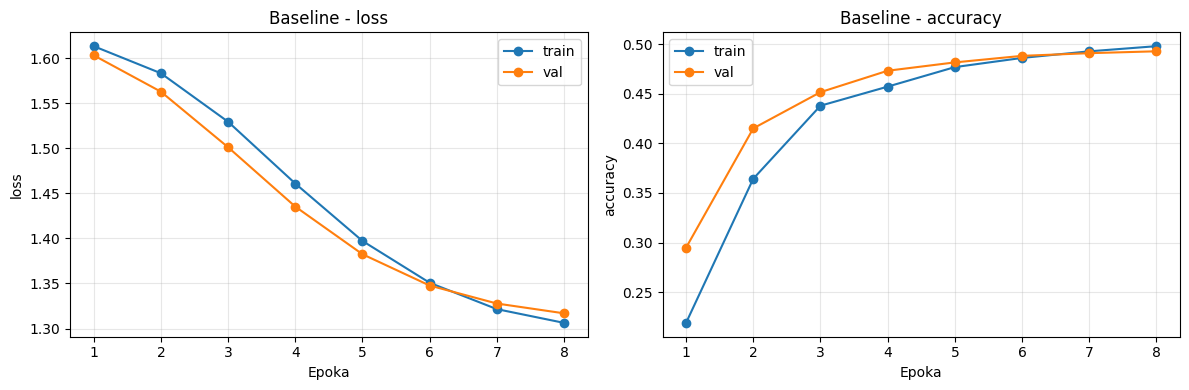

In [26]:
def plot_history(history, title=""):
    epochs = range(1, len(history["train/loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, history[f"train/{metric}"], "o-", label="train")
        ax.plot(epochs, history[f"val/{metric}"], "o-", label="val")
        ax.set_xlabel("Epoka")
        ax.set_ylabel(metric)
        ax.set_title(f"{title} - {metric}")
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_history(history, "Baseline")

# 7. Punkt 1. - funkcja znajdująca i wyświetlająca  k  elementów zbioru testowego dla których model najbardziej się myli, czyli estymuje najmniejsze prawdopodobieństwa prawdziwej klasy.

In [29]:
@torch.inference_mode()
def predict_logits(model, loader):
    model.eval()                     # WAŻNE: bez dropout
    all_logits, all_targets = [], []
    for X_batch, target in loader:
        all_logits.append(model(X_batch.to(device)).cpu())
        all_targets.append(target)
    return torch.cat(all_logits), torch.cat(all_targets)


def true_class_scores(logits, targets, method="logprob"):
    # Ocena "pewności" modelu co do PRAWDZIWEJ klasy każdej opinii.
    # method="logit"   - surowy logit prawdziwej klasy
    # method="logprob" - log-prawdopodobieństwo prawdziwej klasy (log_softmax) - poprawna miara,
    #                    uwzględnia logity wszystkich klas, równe minus stracie CE dla tej opinii
    idx = torch.arange(len(targets))
    if method == "logit":
        return logits[idx, targets]
    return torch.log_softmax(logits, dim=1)[idx, targets]


def show_most_wrong(model, loader, texts, k=5, method="logprob", max_chars=400):
    # Znajduje i wyświetla k opinii z najmniejszą oceną prawdziwej klasy
    logits, targets = predict_logits(model, loader)
    scores = true_class_scores(logits, targets, method)
    probs = torch.softmax(logits, dim=1)

    worst = torch.argsort(scores)[:k]          # indeksy k najmniejszych wartości
    print(f"=== {k} najgorszych przykładów (metoda: {method}) ===\n")
    for rank, i in enumerate(worst.tolist(), 1):
        true_c, pred_c = targets[i].item(), logits[i].argmax().item()
        text = texts[i].replace("\\n", " ")    # usuniecie "\n" z tekstów Yelpa
        print(f"#{rank}  [indeks {i}]  prawdziwa: {class_names[true_c]}  |  predykcja: {class_names[pred_c]}")
        print(f"     P(prawdziwa) = {probs[i, true_c]:.5f}   logit(prawdziwa) = {logits[i, true_c]:.3f}")
        print(f"     Rozkład P: {[round(p, 3) for p in probs[i].tolist()]}")
        print(f"     Tekst: {text[:max_chars]}{'...' if len(text) > max_chars else ''}\n")
    return worst

In [30]:
# liczenie najmniejszego prawdopodobieństwa prawdziwej klasy
worst_logprob = show_most_wrong(model, dataloaders["test"], test_dataset["text"], k=5, method="logprob")

=== 5 najgorszych przykładów (metoda: logprob) ===

#1  [indeks 7189]  prawdziwa: 2 star  |  predykcja: 4 stars
     P(prawdziwa) = 0.07663   logit(prawdziwa) = -0.635
     Rozkład P: [0.054, 0.077, 0.093, 0.421, 0.355]
     Tekst: Love going to Town Square to escape the superficial atmosphere at the strip.   Makes me feel like I am back in Cali.  Love the place and there is always something to do in the day time and evenings.  A great place for kids.  4 big stars

#2  [indeks 7626]  prawdziwa: 3 stars  |  predykcja: 5 stars
     P(prawdziwa) = 0.07847   logit(prawdziwa) = -0.581
     Rozkład P: [0.053, 0.058, 0.078, 0.389, 0.421]
     Tekst: Wonderful experience! I was in town on business, looking for somewhere cozy.  Small, family-owned business, excellent food! I had a nice merlot, wild mushroom soup, beef Wellington, coffee and the lemon tart.  Everything was perfect! I would highly recommend this nice little, very personal restaurant.

#3  [indeks 1064]  prawdziwa: 4 stars  |  pre

In [31]:
# Liczenie najmniejszego logitu prawdziwej klasy
worst_logit = show_most_wrong(model, dataloaders["test"], test_dataset["text"], k=5, method="logit")

=== 5 najgorszych przykładów (metoda: logit) ===

#1  [indeks 1064]  prawdziwa: 4 stars  |  predykcja: 1 star
     P(prawdziwa) = 0.07887   logit(prawdziwa) = -0.720
     Rozkład P: [0.364, 0.245, 0.217, 0.079, 0.094]
     Tekst: Nordstrom Rack has provided me with some pearls over the past year!  I've bought several dresses that were marked down by over $100.  That being said, those deals don't come around every time.  There is also a section of the store that sells the standard items at original price (i.e. tank tops in every color, cardigans, t-shirts, etc.).    Usually I find the staff to be helpful and pleasant; howev...

#2  [indeks 8214]  prawdziwa: 4 stars  |  predykcja: 1 star
     P(prawdziwa) = 0.08192   logit(prawdziwa) = -0.718
     Rozkład P: [0.373, 0.222, 0.214, 0.082, 0.109]
     Tekst: This was our second stop to buy a Camry and once it got over the initial service hiccup, we got a very good deal from a very efficient salesperson.  We got here when it was clearly a ve

In [32]:
# Porównanie metod: ile przykładów wspólnych mają obie listy dla różnych k
logits_test, targets_test = predict_logits(model, dataloaders["test"])
s_logit = true_class_scores(logits_test, targets_test, "logit")
s_logprob = true_class_scores(logits_test, targets_test, "logprob")

for k in [5, 20, 100, 500]:
    a = set(torch.argsort(s_logit)[:k].tolist())
    b = set(torch.argsort(s_logprob)[:k].tolist())
    print(f"k={k:4d}: wspólne przykłady = {len(a & b)}/{k} ({100 * len(a & b) / k:.0f}%)")

k=   5: wspólne przykłady = 3/5 (60%)
k=  20: wspólne przykłady = 17/20 (85%)
k= 100: wspólne przykłady = 78/100 (78%)
k= 500: wspólne przykłady = 427/500 (85%)


In [33]:
#Najmniejszy logit prawdziwej klasy nie jest równoważny najmniejszemu prawdopodobieństwu, bo softmax normalizuje po wszystkich logitach.
#Pokrycie wyników obu metod wyniosło 60–85%. Główne źródła błędów to szum w etykietach oraz opinie mieszane, których worek słów nie rozumie,
#bo ignoruje kolejność słów.

## 8. Punkt 2 – wpływ wybranych parametrów funkcji TfidfVectorizer ekstrakcji cech z tekstu na skuteczność wytrenowanego modelu.

In [34]:
#Cel: sprawdzić, jak sposób zamiany tekstu na liczby wpływa na dokładność modelu na zbiorze walidacyjnym.
#przed sprawdzeniem - uwazam, ze stop_words=None czyli	„not”, „never” zostają - zwiekszy skutecznosc modelu

In [35]:
import gc

def clean_text(text):
    # Usuwa dosłowne "\n" z tekstów Yelpa (źródło tokenów typu "ngetting") i zamienia na małe litery.
    return text.replace("\\n", " ").lower()


def run_tfidf_experiment(name, tfidf_params, num_epochs=8, lr=1e-4):
    # 1) Ekstrakcja cech - fit tylko na train, transform na val
    vec = TfidfVectorizer(**tfidf_params)
    X_train = vec.fit_transform(train_dataset["text"])
    X_val = vec.transform(val_dataset["text"])
    vs = X_train.shape[1]   # faktyczny rozmiar słownika = rozmiar wejścia sieci

    # 2) Dataset i DataLoader (tylko train i val)
    ds = {"train": make_dataset(X_train, train_dataset["label"]),
          "val": make_dataset(X_val, val_dataset["label"])}
    loaders = {s: DataLoader(ds[s], batch_size=batch_size, shuffle=(s == "train"), num_workers=0)
               for s in ds}

    # 3) Świeży model i ta sama konfiguracja uczenia co w baseline
    torch.manual_seed(SEED)
    model = SimpleNet(vs, n_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)

    # 4) Trening z logowaniem do W&B (group grupuje runy punktu 2 w jednym widoku)
    run = wandb.init(project="llm-lab01-yelp", name=f"tfidf-{name}", group="punkt2-tfidf",
                     config={"experiment": name, "vocab_size": vs, **{k: str(v) for k, v in tfidf_params.items()}})
    history = train(model, loaders, criterion, optimizer, scheduler, num_epochs)
    run.finish()

    result = {
        "eksperyment": name,
        "rozmiar słownika": vs,
        "train acc": history["train/accuracy"][-1],
        "val acc": history["val/accuracy"][-1],
        "val loss": history["val/loss"][-1],
    }

    # 5) Zwolnienie pamięci - gęste macierze zajmują GB RAM, a eksperymentów jest kilka
    del vec, X_train, X_val, ds, loaders, model, optimizer
    gc.collect()
    torch.cuda.empty_cache()
    return result, history

In [36]:
# Konfiguracja bazowa - identyczna jak w kroku 3
base = dict(max_features=10_000, lowercase=True, analyzer="word",
            ngram_range=(1, 1), stop_words="english")

# Każdy eksperyment = baza + jedna zmiana ({**base, ...} kopiuje słownik i nadpisuje wybrane klucze)
tfidf_experiments = {
    "baseline":       base,
    "no_stopwords":   {**base, "stop_words": None},
    "bigrams":        {**base, "stop_words": None, "ngram_range": (1, 2)},
    "vocab_5k":       {**base, "max_features": 5_000},
    "vocab_20k":      {**base, "max_features": 20_000},
    "sublinear_tf":   {**base, "sublinear_tf": True},
    "clean_newlines": {**base, "preprocessor": clean_text},
}

tfidf_results, tfidf_histories = [], {}
for name, params in tfidf_experiments.items():
    print(f"\n{'=' * 20} {name} {'=' * 20}")
    result, hist = run_tfidf_experiment(name, params)
    tfidf_results.append(result)        # wyniki dopisywane na bieżąco - nie przepadną, jeśli coś się wysypie
    tfidf_histories[name] = hist


==================== baseline ====================


Epoka 1 [train]:   0%|          | 0/196 [00:00<?, ?it/s]

Epoka 1/8 [train]  loss: 1.6133  accuracy: 0.2191  lr: 1.00e-04


Epoka 1 [val]:   0%|          | 0/40 [00:00<?, ?it/s]

Epoka 1/8 [val  ]  loss: 1.6031  accuracy: 0.2948  lr: 1.00e-04


Epoka 2 [train]:   0%|          | 0/196 [00:00<?, ?it/s]

... (228 outputs left out)

Epoka 8/8 [train]  loss: 1.3049  accuracy: 0.4931  lr: 1.34e-05


Epoka 8 [val]:   0%|          | 0/40 [00:00<?, ?it/s]

Epoka 8/8 [val  ]  loss: 1.3145  accuracy: 0.4880  lr: 1.34e-05


lr,██▇▆▄▃▂▁
train/accuracy,▁▅▆▇▇███
train/loss,█▇▆▄▃▂▁▁
val/accuracy,▁▅▆▇▇███
val/loss,█▇▅▄▃▂▁▁
lr,1e-05
train/accuracy,0.49306
train/loss,1.30487
val/accuracy,0.488
val/loss,1.3145


,eksperyment,rozmiar słownika,train acc,val acc,val loss,różnica vs baseline [pp]
2,bigrams,10000,0.5172,0.5272,1.2268,3.44
1,no_stopwords,10000,0.5022,0.5098,1.2783,1.70
3,vocab_5k,5000,0.4971,0.5017,1.2486,0.89
5,sublinear_tf,10000,0.4995,0.4973,1.3103,0.45
0,baseline,10000,0.4980,0.4928,1.3169,0.00
6,clean_newlines,10000,0.4931,0.4880,1.3145,-0.48
4,vocab_20k,20000,0.4775,0.4681,1.3145,-2.47


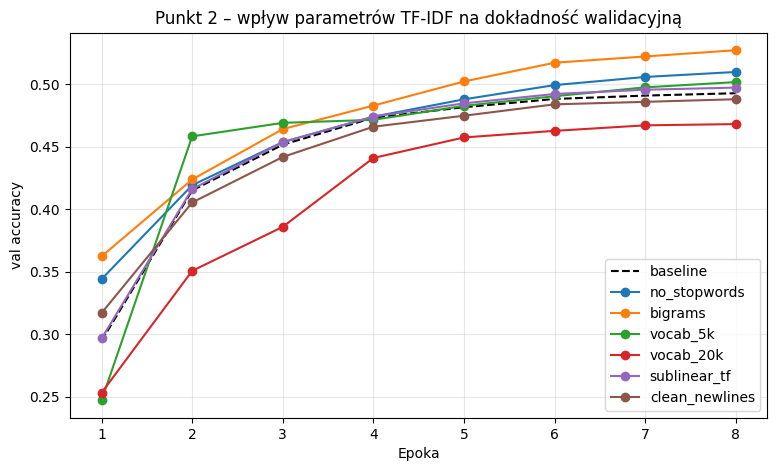

In [37]:
# Zestawienie wyników - posortowane od najlepszej dokładności walidacyjnej
import pandas as pd

df_tfidf = pd.DataFrame(tfidf_results).sort_values("val acc", ascending=False)
df_tfidf["różnica vs baseline [pp]"] = 100 * (df_tfidf["val acc"] - df_tfidf.loc[df_tfidf["eksperyment"] == "baseline", "val acc"].item())
display(df_tfidf.round(4))

# Krzywe dokładności walidacyjnej wszystkich wariantów na jednym wykresie
plt.figure(figsize=(9, 5))
for name, hist in tfidf_histories.items():
    style = "k--" if name == "baseline" else "o-"
    plt.plot(range(1, len(hist["val/accuracy"]) + 1), hist["val/accuracy"], style, label=name)
plt.xlabel("Epoka")
plt.ylabel("val accuracy")
plt.title("Punkt 2 – wpływ parametrów TF-IDF na dokładność walidacyjną")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [39]:
#Największy wpływ miało zachowanie słów przeczących i dodanie bigramów (+3,4 pp), bo pozwala to uchwycić zaprzeczenia.
#Pozorna przewaga mniejszego słownika wynika z niedouczenia modeli: większa pierwsza warstwa uczy się
#wolniej przy stałym lr i liczbie epok. Różnice poniżej ok. 1 pp mieszczą się w niepewności pomiaru.


hipotezy = {
    "baseline":       ("brak (10k słów, unigramy, bez stop words)", "punkt odniesienia, ok. 49,3%"),
    "no_stopwords":   ("stop_words=None", "„not”, „never” zostają, więc może być lepiej"),
    "bigrams":        ("ngram_range=(1, 2) + stop_words=None", "pary słów („not good”) niosą zaprzeczenia"),
    "vocab_5k":       ("max_features=5000", "mniej informacji, ale mniejszy model"),
    "vocab_20k":      ("max_features=20000", "więcej słów, ale więcej parametrów do nauczenia"),
    "sublinear_tf":   ("sublinear_tf=True", "TF = 1 + log(tf): powtórzenia słowa mniej dominują"),
    "clean_newlines": ("czyszczenie \\n z tekstu", "znikają śmieciowe tokeny w rodzaju „ngetting”"),
}

df_plan = pd.DataFrame(
    [(n, z, h) for n, (z, h) in hipotezy.items()],
    columns=["eksperyment", "zmiana", "hipoteza"],
)
df_summary = df_plan.merge(df_tfidf[["eksperyment", "val acc", "różnica vs baseline [pp]"]], on="eksperyment")
df_summary["val acc"] = (100 * df_summary["val acc"]).round(2)
df_summary["różnica vs baseline [pp]"] = df_summary["różnica vs baseline [pp]"].round(2)

pd.set_option("display.max_colwidth", None)   # pokaż pełne teksty w kolumnach
display(df_summary.sort_values("val acc", ascending=False))

,eksperyment,zmiana,hipoteza,val acc,różnica vs baseline [pp]
2,bigrams,"ngram_range=(1, 2) + stop_words=None",pary słów („not good”) niosą zaprzeczenia,52.72,3.44
1,no_stopwords,stop_words=None,"„not”, „never” zostają, więc może być lepiej",50.98,1.70
3,vocab_5k,max_features=5000,"mniej informacji, ale mniejszy model",50.17,0.89
5,sublinear_tf,sublinear_tf=True,TF = 1 + log(tf): powtórzenia słowa mniej dominują,49.73,0.45
0,baseline,"brak (10k słów, unigramy, bez stop words)","punkt odniesienia, ok. 49,3%",49.28,0.00
6,clean_newlines,czyszczenie \n z tekstu,znikają śmieciowe tokeny w rodzaju „ngetting”,48.80,-0.48
4,vocab_20k,max_features=20000,"więcej słów, ale więcej parametrów do nauczenia",46.81,-2.47


## 9. Punkt 3 – wpływ hiperparametrów modelu i procesu uczenia na skuteczność wytrenowanego modelu.

In [40]:
#**Metoda:**
#- Cechy: najlepsza konfiguracja TF-IDF z punktu 2 (unigramy + bigramy, bez usuwania stop words, 10k cech).
#- **Etap A** – parametry procesu uczenia (stopa uczenia, liczba epok, optymalizator), zmieniane pojedynczo względem konfiguracji bazowej.
#- **Etap B** – na najlepszej konfiguracji z etapu A: architektura sieci (liczba i rozmiar warstw, dropout) oraz planista stopy uczenia.
#- **Etap C** – finalna ewaluacja najlepszego modelu na zbiorze testowym (jednokrotnie).

In [41]:
# Cechy dla punktu 3: zwycięska konfiguracja TF-IDF z punktu 2 (bigramy, bez usuwania stop words).
# Zwolnienie pamięci po cechach z kroków 3-6 (baseline) - gęste macierze zajmują GB RAM
del datasets, dataloaders, train_tfidf, val_tfidf, test_tfidf
gc.collect()

best_tfidf_params = tfidf_experiments["bigrams"]
feat_vectorizer = TfidfVectorizer(**best_tfidf_params)

X_train = feat_vectorizer.fit_transform(train_dataset["text"])   # fit tylko na train
X_val = feat_vectorizer.transform(val_dataset["text"])
X_test = feat_vectorizer.transform(test_dataset["text"])          # test przygotowany, ale użyty dopiero w etapie C
feat_vocab_size = X_train.shape[1]

feat_datasets = {
    "train": make_dataset(X_train, train_dataset["label"]),
    "val": make_dataset(X_val, val_dataset["label"]),
    "test": make_dataset(X_test, test_dataset["label"]),
}
feat_loaders = {
    s: DataLoader(feat_datasets[s], batch_size=batch_size, shuffle=(s == "train"), num_workers=0)
    for s in feat_datasets
}
del X_train, X_val, X_test
gc.collect()

print(f"Rozmiar słownika: {feat_vocab_size}")
print(f"Przykładowe bigramy w słowniku: {[w for w in feat_vectorizer.get_feature_names_out() if ' ' in w][:15]}")

Rozmiar słownika: 10000
Przykładowe bigramy w słowniku: ['00 for', '10 15', '10 and', '10 for', '10 minutes', '10 years', '15 20', '15 minutes', '20 for', '20 minutes', '24 hour', '24 hours', '25 minutes', '30 and', '30 min']


In [42]:
def make_optimizer(model, cfg):
    if cfg["optimizer"] == "adamw":
        # AdamW - adaptacyjna stopa uczenia dla każdego parametru osobno
        return torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    if cfg["optimizer"] == "sgd":
        # SGD z momentum - klasyczny spadek gradientu z "bezwładnością" (uśrednianie kierunku kroków)
        return torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9, weight_decay=cfg["weight_decay"])
    raise ValueError(cfg["optimizer"])


def make_scheduler(optimizer, cfg):
    n = cfg["num_epochs"]
    if cfg["scheduler"] == "cosine":
        # lr maleje po cosinusie od lr do lr/10 (dla lr=1e-4 to dokładnie eta_min=1e-5 jak w baseline)
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n, eta_min=cfg["lr"] / 10)
    if cfg["scheduler"] == "step":
        # lr maleje skokowo 10x co 1/3 treningu
        return torch.optim.lr_scheduler.StepLR(optimizer, step_size=max(1, n // 3), gamma=0.1)
    if cfg["scheduler"] == "none":
        # stała stopa uczenia (mnożnik 1.0 w każdej epoce)
        return torch.optim.lr_scheduler.LambdaLR(optimizer, lambda epoch: 1.0)
    raise ValueError(cfg["scheduler"])


def run_experiment(name, cfg, group):
    torch.manual_seed(SEED)   # te same wagi startowe i ta sama kolejność batchy w każdym eksperymencie
    model = SimpleNet(feat_vocab_size, n_classes, cfg["hidden_sizes"], cfg["dropout"]).to(device)
    n_params = sum(p.numel() for p in model.parameters())

    criterion = nn.CrossEntropyLoss()
    optimizer = make_optimizer(model, cfg)
    scheduler = make_scheduler(optimizer, cfg)

    run = wandb.init(project="llm-lab01-yelp", name=f"{group}-{name}", group=group,
                     config={**cfg, "n_params": n_params, "experiment": name})
    history = train(model, feat_loaders, criterion, optimizer, scheduler, cfg["num_epochs"])
    run.finish()

    val_acc = history["val/accuracy"]
    result = {
        "eksperyment": name,
        "val acc": val_acc[-1],                          # po ostatniej epoce - tym modelem dysponujemy
        "val acc max": max(val_acc),                     # najlepsza epoka - czy model się przeuczał?
        "najlepsza epoka": int(np.argmax(val_acc)) + 1,
        "train acc": history["train/accuracy"][-1],
        "parametry": n_params,
    }
    # Zapamiętujemy wagi (na CPU, ok. kilka MB) - najlepszy model ocenimy w etapie C na teście
    state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    del model, optimizer
    torch.cuda.empty_cache()
    return result, history, state


def show_results(results, histories, title, ref="base"):
    # Tabela posortowana po val acc + krzywe dokładności walidacyjnej
    df = pd.DataFrame(results).sort_values("val acc", ascending=False)
    ref_acc = df.loc[df["eksperyment"] == ref, "val acc"].item()
    df["różnica vs " + ref + " [pp]"] = 100 * (df["val acc"] - ref_acc)
    df["luka train-val [pp]"] = 100 * (df["train acc"] - df["val acc"])   # duża luka = przeuczenie
    display(df.round(4))

    plt.figure(figsize=(9, 5))
    for name, hist in histories.items():
        style = "k--" if name == ref else "o-"
        plt.plot(range(1, len(hist["val/accuracy"]) + 1), hist["val/accuracy"], style, label=name)
    plt.xlabel("Epoka"); plt.ylabel("val accuracy"); plt.title(title)
    plt.grid(alpha=0.3); plt.legend(); plt.show()
    return df

In [46]:
# etap A
# Konfiguracja bazowa
base_cfg = dict(hidden_sizes=(64, 16), dropout=0.1, lr=1e-4, num_epochs=8,
                optimizer="adamw", weight_decay=1e-5, scheduler="cosine")

# Etap A: każdy eksperyment = base + jedna zmiana w procesie uczenia.
# Wyjątek: SGD wymaga innego lr niż AdamW (AdamW sam skaluje kroki, SGD nie),
# więc zmiana optymalizatora pociąga za sobą lr typowe dla SGD.
stage_a = {
    "base":      base_cfg,
    "lr_1e-3":   {**base_cfg, "lr": 1e-3},
    "lr_3e-3":   {**base_cfg, "lr": 3e-3},
    "epochs_20": {**base_cfg, "num_epochs": 20},
    "sgd":       {**base_cfg, "optimizer": "sgd", "lr": 0.05},
}

results_a, histories_a, states = [], {}, {}
for name, cfg in stage_a.items():
    print(f"\n{'=' * 20} A: {name} {'=' * 20}")
    res, hist, state = run_experiment(name, cfg, group="punkt3-A")
    results_a.append(res)
    histories_a[name] = hist
    states[name] = (cfg, state)     # konfiguracja + wagi - do wyboru najlepszego modelu w etapie C


==================== A: base ====================


Epoka 1 [train]:   0%|          | 0/196 [00:00<?, ?it/s]

Epoka 1/8 [train]  loss: 1.6112  accuracy: 0.2542  lr: 1.00e-04


Epoka 1 [val]:   0%|          | 0/40 [00:00<?, ?it/s]

Epoka 1/8 [val  ]  loss: 1.5989  accuracy: 0.3623  lr: 1.00e-04


Epoka 2 [train]:   0%|          | 0/196 [00:00<?, ?it/s]

... (208 outputs left out)

Epoka 8/8 [train]  loss: 0.8871  accuracy: 0.6119  lr: 6.71e-03


Epoka 8 [val]:   0%|          | 0/40 [00:00<?, ?it/s]

Epoka 8/8 [val  ]  loss: 0.9394  accuracy: 0.5925  lr: 6.71e-03


lr,██▇▆▄▃▂▁
train/accuracy,▁▂▄▆▇███
train/loss,██▅▃▂▁▁▁
val/accuracy,▁▄▅▇▇███
val/loss,█▇▄▂▂▁▁▁
lr,0.00671
train/accuracy,0.61188
train/loss,0.88706
val/accuracy,0.5925
val/loss,0.93944


,eksperyment,val acc,val acc max,najlepsza epoka,train acc,parametry,różnica vs base [pp],luka train-val [pp]
3,epochs_20,0.5966,0.5967,16,0.6103,641189,6.94,1.374
4,sgd,0.5925,0.5976,7,0.6119,641189,6.53,1.938
1,lr_1e-3,0.5865,0.6036,2,0.7021,641189,5.93,11.564
2,lr_3e-3,0.5647,0.5994,1,0.8088,641189,3.75,24.406
0,base,0.5272,0.5272,8,0.5172,641189,0.00,-1.004


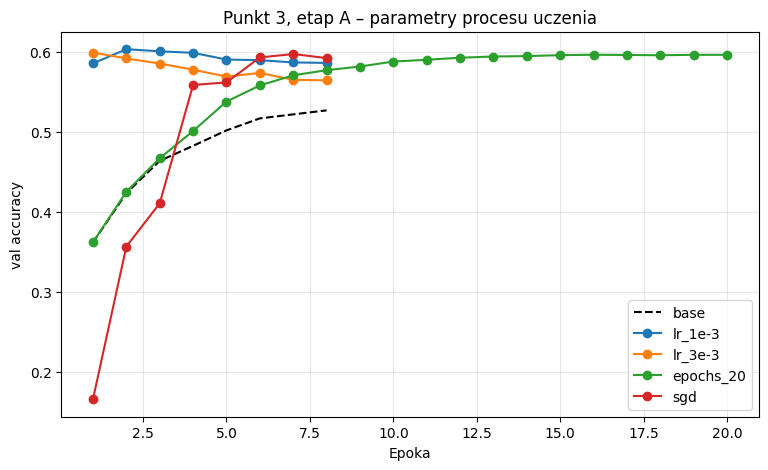

In [47]:
df_a = show_results(results_a, histories_a, "Punkt 3, etap A – parametry procesu uczenia")

In [ ]:
#Zwiększenie lr przyspiesza uczenie (maksimum już w 1.–2. epoce), ale prowadzi do przeuczenia.
#Mały lr z dłuższym treningiem osiąga podobną dokładność stabilnie, bez przeuczenia.
#Wszystkie konfiguracje osiągają ok. 60%, co wskazuje na ograniczenie reprezentacji bag-of-words, a nie procesu uczenia.